# Crop Yield Prediction — India & China
### ML Model Design → URL Generation (Steps 1–10 in this notebook)

| Step | Where |
|---|---|
| 1–10 Problem → Model Saving | **this notebook** |
| 11 Backend (FastAPI) | `backend/main.py` |
| 12 Frontend | `frontend/` |
| 13 Integration | frontend `fetch()` → `/predict` |
| 14 Testing | `tests/test_api.py` |
| 15–16 Deployment & URL | `README.md` |

## Step 1 — Problem Definition

**Goal:** predict the **yield (tonnes per hectare)** of a crop in India or China for a given year.

* **Type:** supervised **regression** (target is a continuous number).
* **Target:** `yield_t_ha`
* **Inputs:** country, crop, year, harvested area, and the year's temperature change (annual + 4 seasons).
* **Why it matters:** yield is the main measure of farm productivity; seeing how it moves with
  warming helps planning for food security.
* **Success metric:** R² (how much variation we explain) and MAE (average error in t/ha) on
  **future years the model has never seen**.

## Step 2 — Data Collection

Two public FAOSTAT-style datasets were collected:

1. **Crops** — area harvested, yield and production per country/crop/year (`india_china_cleaned.csv`)
2. **Weather** — temperature change vs. the 1951–1980 baseline per country/year (`weather_cleaned_5countries.csv`)

They were merged on `country` + `year` (only India and China kept). The merge code from the
original notebook is kept below for reference; its output is `df_perfect_india_china.csv`, which we load here.

In [1]:
# --- original merge code (needs the two raw files; kept for reference) ---
# crops   = pd.read_csv("india_china_cleaned.csv")
# weather = pd.read_csv("weather_cleaned_5countries.csv")
# weather = weather[weather["country"].isin(["India", "China"])]
# weather = weather.drop(columns=[c for c in weather.columns if c.startswith("temp_std")])
# df = crops.merge(weather, on=["country", "year"], how="inner")
# df = df.drop(columns=[c for c in df.columns if c.endswith("_y")])
# df = df.rename(columns={c: c[:-2] for c in df.columns if c.endswith("_x")})
# df.to_csv("df_perfect_india_china.csv", index=False)

import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/df_perfect_india_china.csv")
print(df.shape)
df.head()

(11809, 12)


,country,crop,year,area_harvested_ha,yield_t_ha,production_t,yield_flag,temp_change_annual_c,temp_change_djf_c,temp_change_mam_c,temp_change_jja_c,temp_change_son_c
0,China,"Almonds, in shell",1985,7700.0,1.6883,13000.0,E,-0.125,-0.351,-0.029,0.069,-0.188
1,China,"Almonds, in shell",1986,8300.0,1.6867,14000.0,E,-0.040,0.133,0.120,0.047,-0.459
2,China,"Almonds, in shell",1987,8900.0,1.6854,15000.0,E,0.433,1.585,0.074,-0.114,0.185
3,China,"Almonds, in shell",1988,8600.0,1.6860,14500.0,E,0.400,0.906,-0.397,0.455,0.635
4,China,"Almonds, in shell",1989,9400.0,1.7021,16000.0,E,0.432,1.181,0.343,-0.187,0.388


## Step 3 — Data Preprocessing
Check types, missing values, duplicates, impossible values and outliers.

In [2]:
df.info()
print("\nmissing values :", df.isna().sum().sum())
print("duplicates     :", df.duplicated(["country", "crop", "year"]).sum())
print("zero/negative  :", ((df.yield_t_ha <= 0) | (df.area_harvested_ha <= 0)).sum())

<class 'pandas.DataFrame'>
RangeIndex: 11809 entries, 0 to 11808
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   country               11809 non-null  str    
 1   crop                  11809 non-null  str    
 2   year                  11809 non-null  int64  
 3   area_harvested_ha     11809 non-null  float64
 4   yield_t_ha            11809 non-null  float64
 5   production_t          11809 non-null  float64
 6   yield_flag            11809 non-null  str    
 7   temp_change_annual_c  11809 non-null  float64
 8   temp_change_djf_c     11809 non-null  float64
 9   temp_change_mam_c     11809 non-null  float64
 10  temp_change_jja_c     11809 non-null  float64
 11  temp_change_son_c     11809 non-null  float64
dtypes: float64(8), int64(1), str(3)
memory usage: 1.1 MB

missing values : 0
duplicates     : 0
zero/negative  : 0


In [3]:
df["yield_t_ha"].describe()

count    11809.000000
mean         9.379470
std         52.838453
min          0.038200
25%          1.353200
50%          4.175500
75%         11.759600
max       5415.789500
Name: yield_t_ha, dtype: float64

In [4]:
# Yields above 100 t/ha are not physically realistic for field crops.
# They all come from one aggregated FAO category ("Other stimulant, spice and aromatic crops, n.e.c.").
print(df.loc[df["yield_t_ha"] > 100, "crop"].value_counts())
print((df["yield_t_ha"] > 100).sum(), "rows to remove")

df = df[df["yield_t_ha"] <= 100].reset_index(drop=True)
print("new shape:", df.shape, "| max yield:", df["yield_t_ha"].max())

crop
Other stimulant, spice and aromatic crops, n.e.c.    24
Spinach                                               1
Name: count, dtype: int64
25 rows to remove
new shape: (11784, 12) | max yield: 84.9063


## Step 4 — Exploratory Data Analysis (EDA)

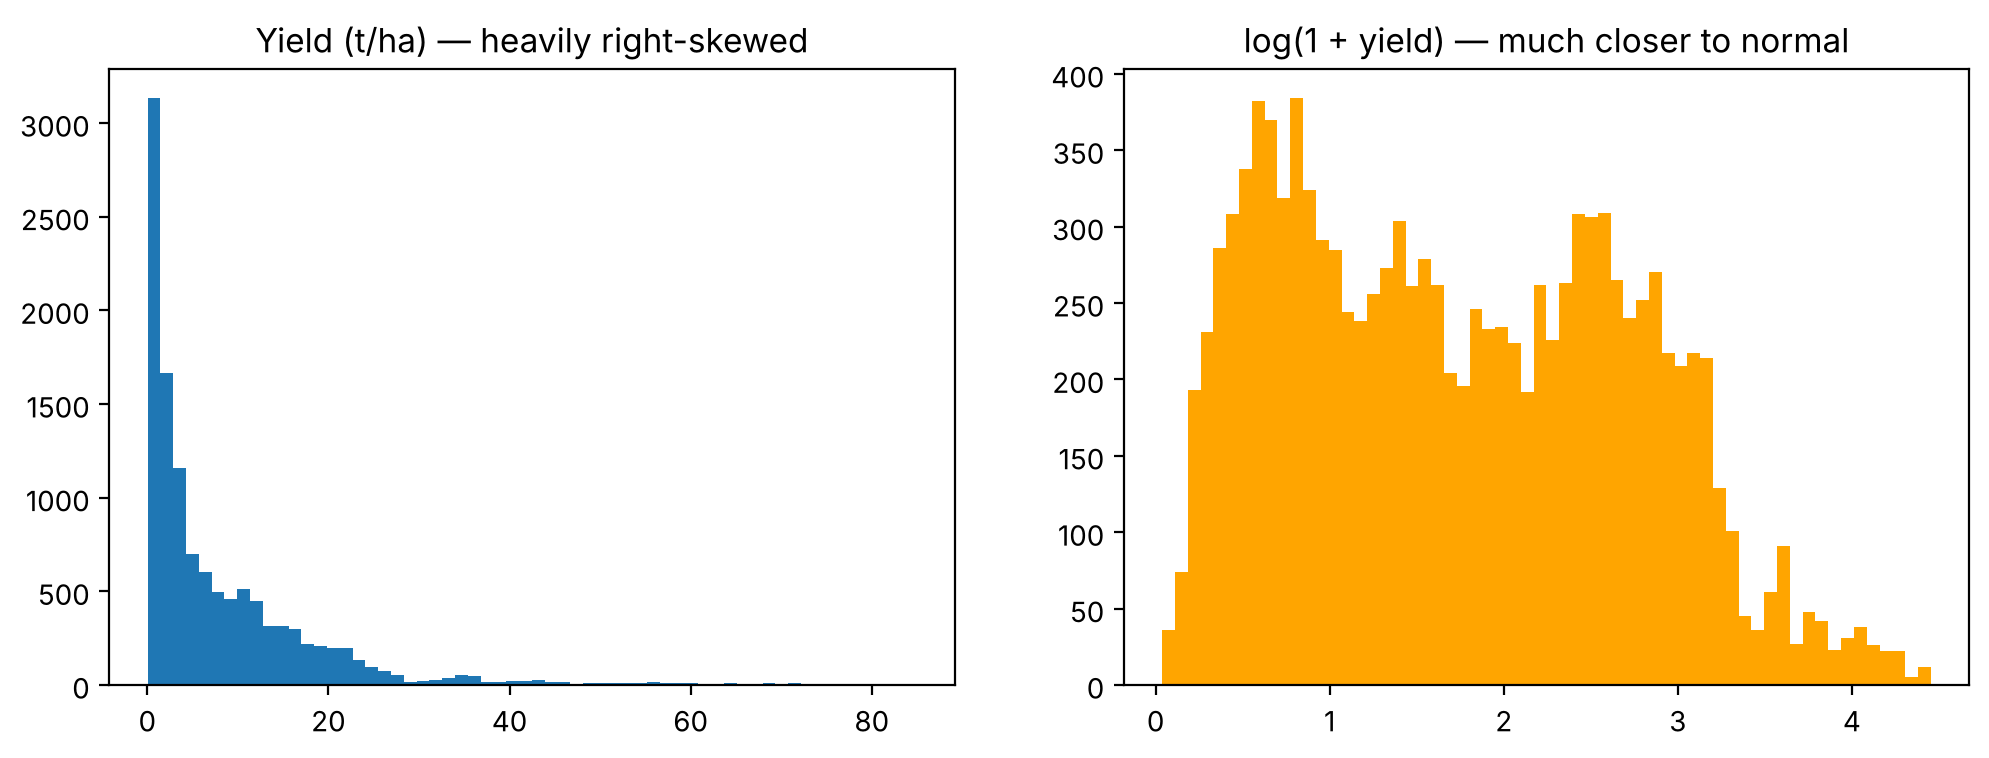

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["yield_t_ha"], bins=60)
ax[0].set_title("Yield (t/ha) — heavily right-skewed")
ax[1].hist(np.log1p(df["yield_t_ha"]), bins=60, color="orange")
ax[1].set_title("log(1 + yield) — much closer to normal")
plt.show()

**Observation:** yield is strongly skewed (a few crops like sugar cane or vegetables yield 50–80 t/ha,
most crops yield 1–5 t/ha). We will train on **log(1 + yield)** and convert back with `expm1`.

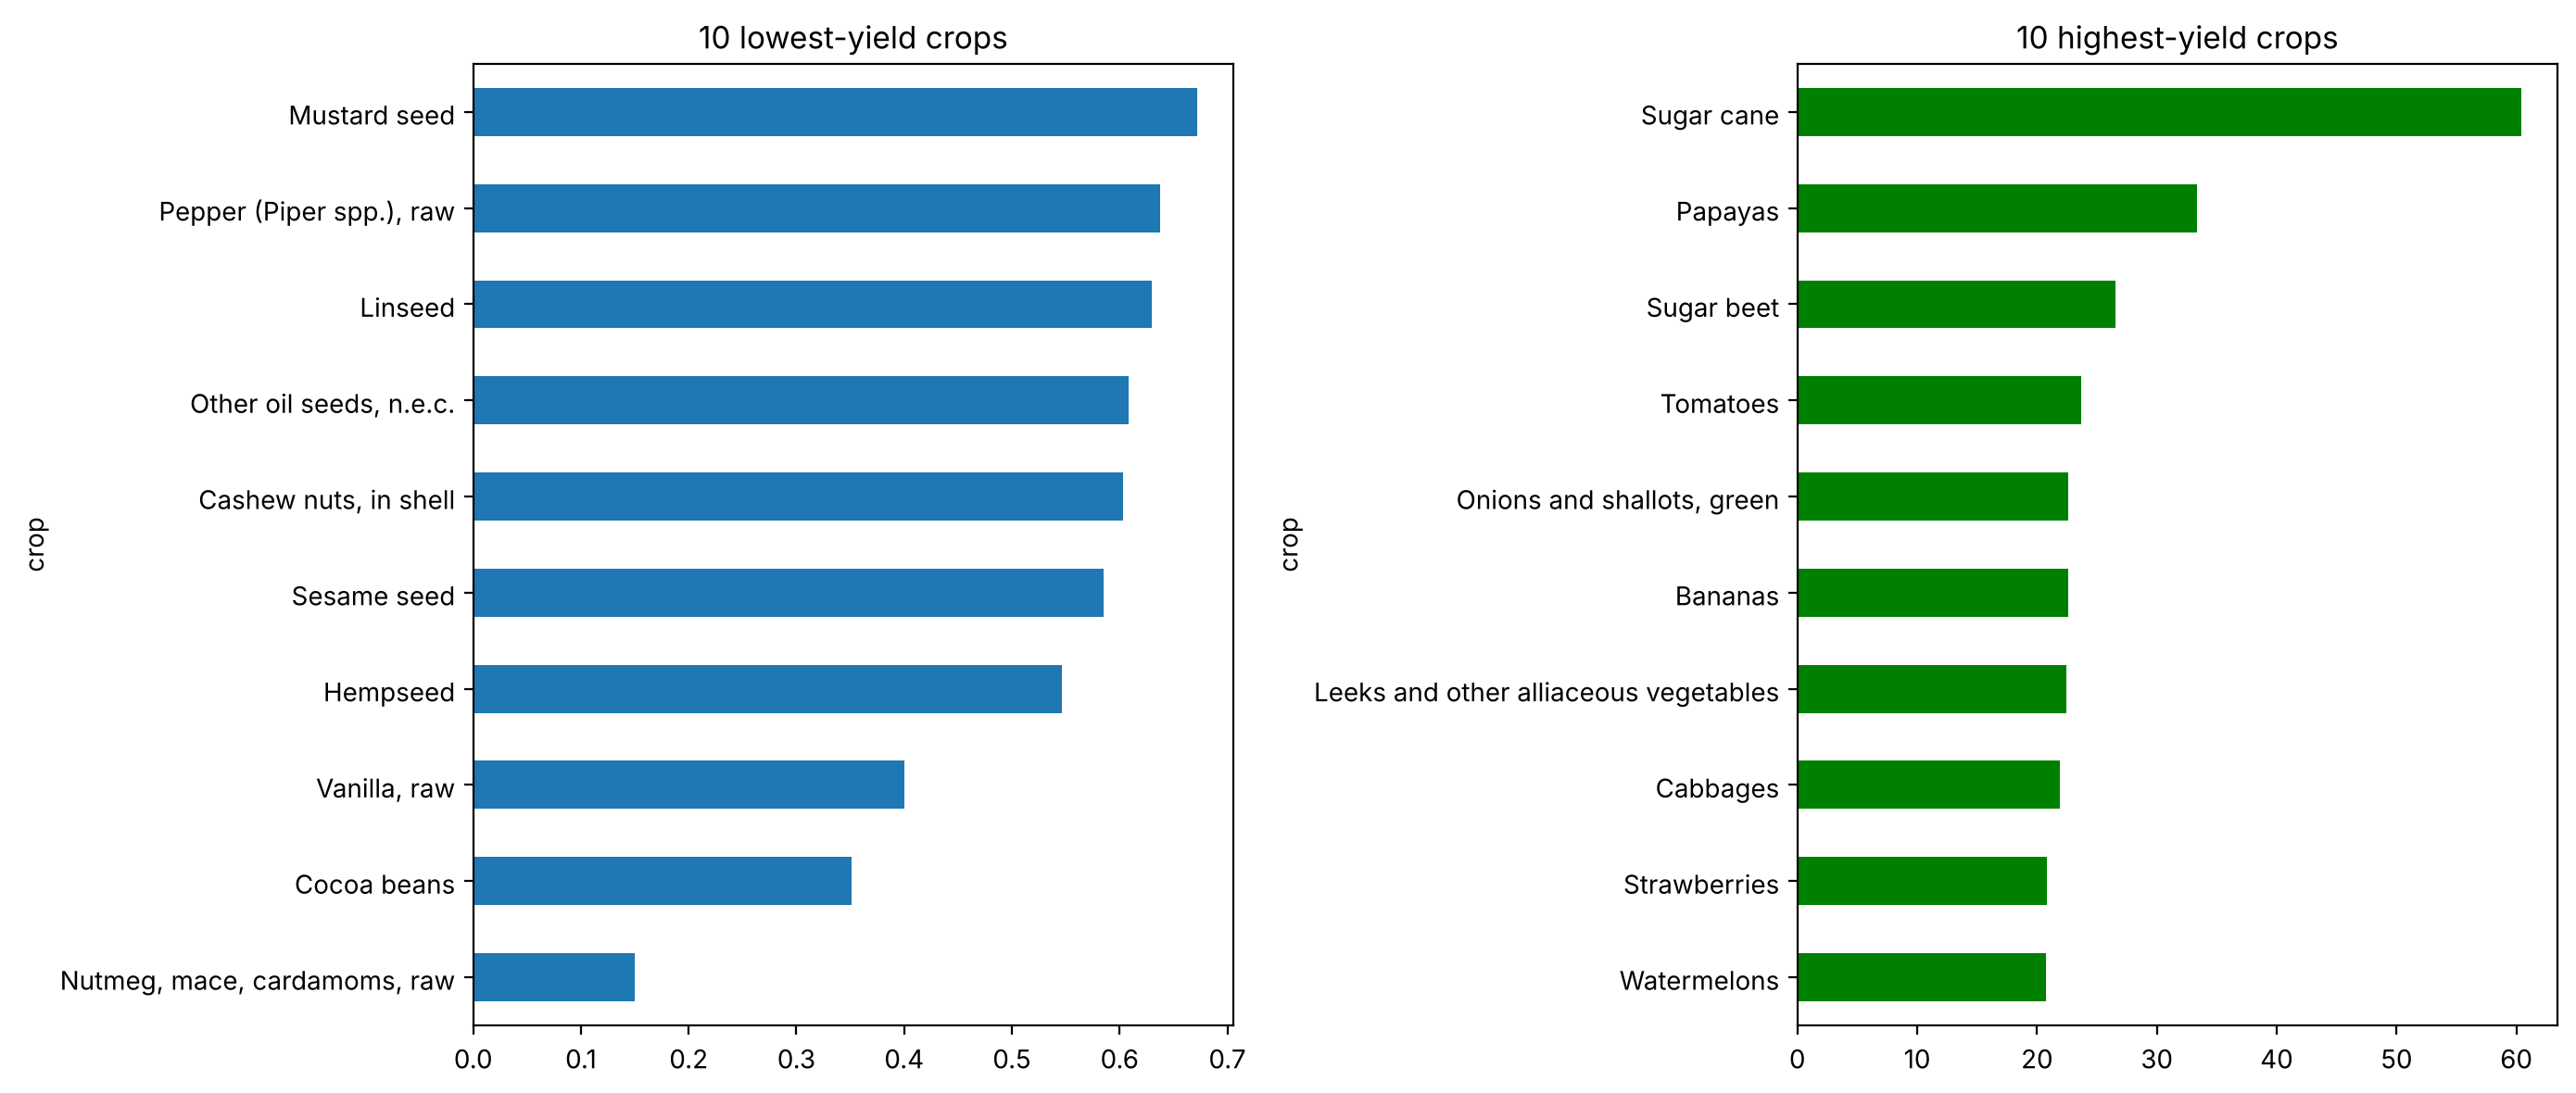

In [6]:
top = df.groupby("crop")["yield_t_ha"].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top.head(10).plot.barh(ax=ax[0], title="10 lowest-yield crops")
top.tail(10).plot.barh(ax=ax[1], color="green", title="10 highest-yield crops")
plt.tight_layout(); plt.show()

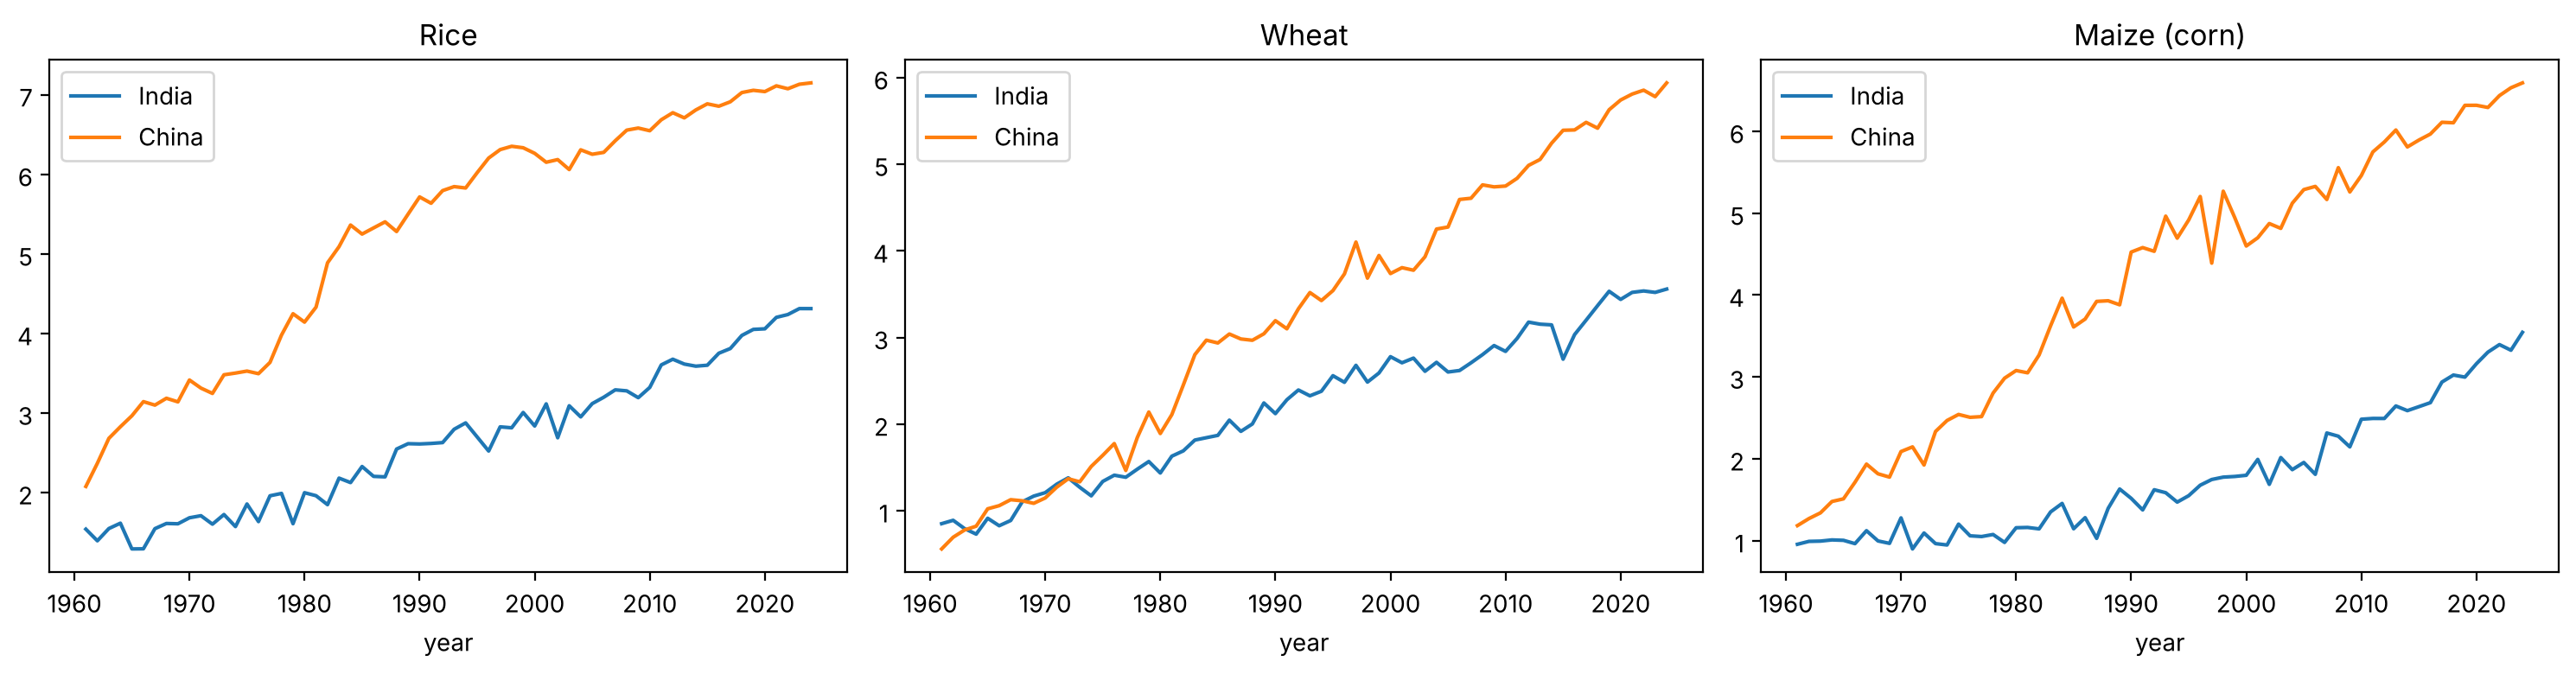

In [7]:
crops_to_plot = ["Rice", "Wheat", "Maize (corn)"]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(crops_to_plot):
    for country in ["India", "China"]:
        d = df[(df["crop"] == c) & (df["country"] == country)]
        ax[i].plot(d["year"], d["yield_t_ha"], label=country)
    ax[i].set_title(c); ax[i].set_xlabel("year"); ax[i].legend()
plt.tight_layout(); plt.show()

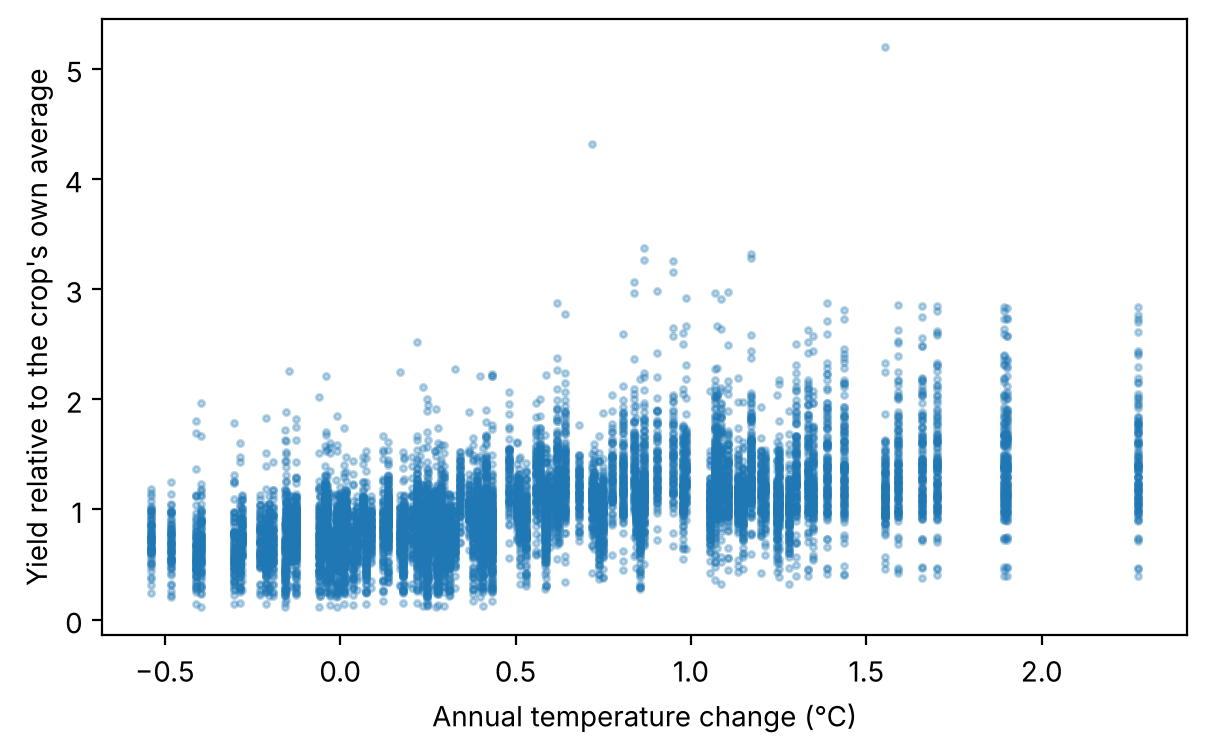

year                    0.665
area_harvested_ha       0.023
temp_change_annual_c    0.560
temp_change_djf_c       0.390
temp_change_mam_c       0.476
temp_change_jja_c       0.515
temp_change_son_c       0.507
yield_rel               1.000
Name: yield_rel, dtype: float64


In [8]:
d = df.copy()
d["yield_rel"] = d["yield_t_ha"] / d.groupby(["country", "crop"])["yield_t_ha"].transform("mean")
plt.figure(figsize=(7, 4))
plt.scatter(d["temp_change_annual_c"], d["yield_rel"], s=5, alpha=0.3)
plt.xlabel("Annual temperature change (°C)")
plt.ylabel("Yield relative to the crop's own average")
plt.show()

num_cols = ["year", "area_harvested_ha", "temp_change_annual_c", "temp_change_djf_c",
            "temp_change_mam_c", "temp_change_jja_c", "temp_change_son_c"]
print(d[num_cols + ["yield_rel"]].corr()["yield_rel"].round(3))

**Observations**
* Yields rise steadily over time for both countries (better seeds, irrigation, fertiliser) → `year` is important.
* Temperature change is also rising over time, so it is **correlated with year** — the model must separate the two.
* The crop itself decides most of the yield level → `crop` must be a feature.

## Step 5 — Feature Engineering

| Decision | Reason |
|---|---|
| **Drop `production_t`** | production = area × yield → it would *leak* the answer |
| **Drop `yield_flag`** | a data-quality flag from FAO, not known when predicting |
| `log_area = log(1 + area_harvested_ha)` | area ranges from 10 ha to 40 million ha |
| One-hot encode `country`, `crop` | text categories → numbers |
| Scale numeric columns | needed for linear models (harmless for trees) |
| Target = `log1p(yield_t_ha)` | removes the skew seen in EDA |

In [9]:
df["log_area"] = np.log1p(df["area_harvested_ha"])

CAT_FEATURES = ["country", "crop"]
NUM_FEATURES = ["year", "log_area", "temp_change_annual_c", "temp_change_djf_c",
                "temp_change_mam_c", "temp_change_jja_c", "temp_change_son_c"]
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "yield_t_ha"

# Time-based split: train on the past, test on the most recent 10 years.
# (A random split would let the model "peek" at neighbouring years of the same crop.)
train = df[df["year"] <= 2014].sort_values("year").reset_index(drop=True)
test  = df[df["year"] >  2014].reset_index(drop=True)

X_train, y_train = train[FEATURES], np.log1p(train[TARGET])
X_test,  y_test  = test[FEATURES],  test[TARGET]          # y_test kept in real t/ha
print("train:", X_train.shape, f"({train.year.min()}–{train.year.max()})")
print("test :", X_test.shape,  f"({test.year.min()}–{test.year.max()})")

train: (9802, 9) (1961–2014)
test : (1982, 9) (2015–2024)


In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
])

## Step 6 — Model Selection

We compare three algorithms of increasing power, plus a simple **baseline**
(predict each crop's historical average yield in that country). A model is only useful if it beats the baseline.

In [11]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def evaluate(name, y_true, y_pred):
    return {"model": name,
            "R2": r2_score(y_true, y_pred),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5}

# Baseline: historical mean yield of the same crop + country
hist_mean = train.groupby(["country", "crop"])[TARGET].mean()
baseline_pred = test.set_index(["country", "crop"]).index.map(hist_mean)
baseline_pred = pd.Series(baseline_pred).fillna(train[TARGET].mean()).values

candidates = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, n_jobs=-1, random_state=42),
}

## Step 7 — Model Training

In [12]:
import time
results = [evaluate("Baseline (crop average)", y_test, baseline_pred)]
fitted = {}
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    t0 = time.time()
    pipe.fit(X_train, y_train)
    pred = np.expm1(pipe.predict(X_test))          # back to t/ha
    fitted[name] = (pipe, pred)
    results.append(evaluate(name, y_test, pred))
    print(f"{name:25s} trained in {time.time() - t0:5.1f}s")

Ridge Regression          trained in   0.0s


Hist Gradient Boosting    trained in   0.7s


Random Forest             trained in   8.0s


## Step 8 — Model Evaluation

In [13]:
results_df = pd.DataFrame(results).set_index("model").round(3)
results_df.sort_values("R2", ascending=False)

,R2,MAE,RMSE
model,,,
Random Forest,0.926,2.026,3.826
Hist Gradient Boosting,0.807,3.236,6.164
Ridge Regression,0.794,3.351,6.366
Baseline (crop average),0.671,4.303,8.044


Best model: Random Forest


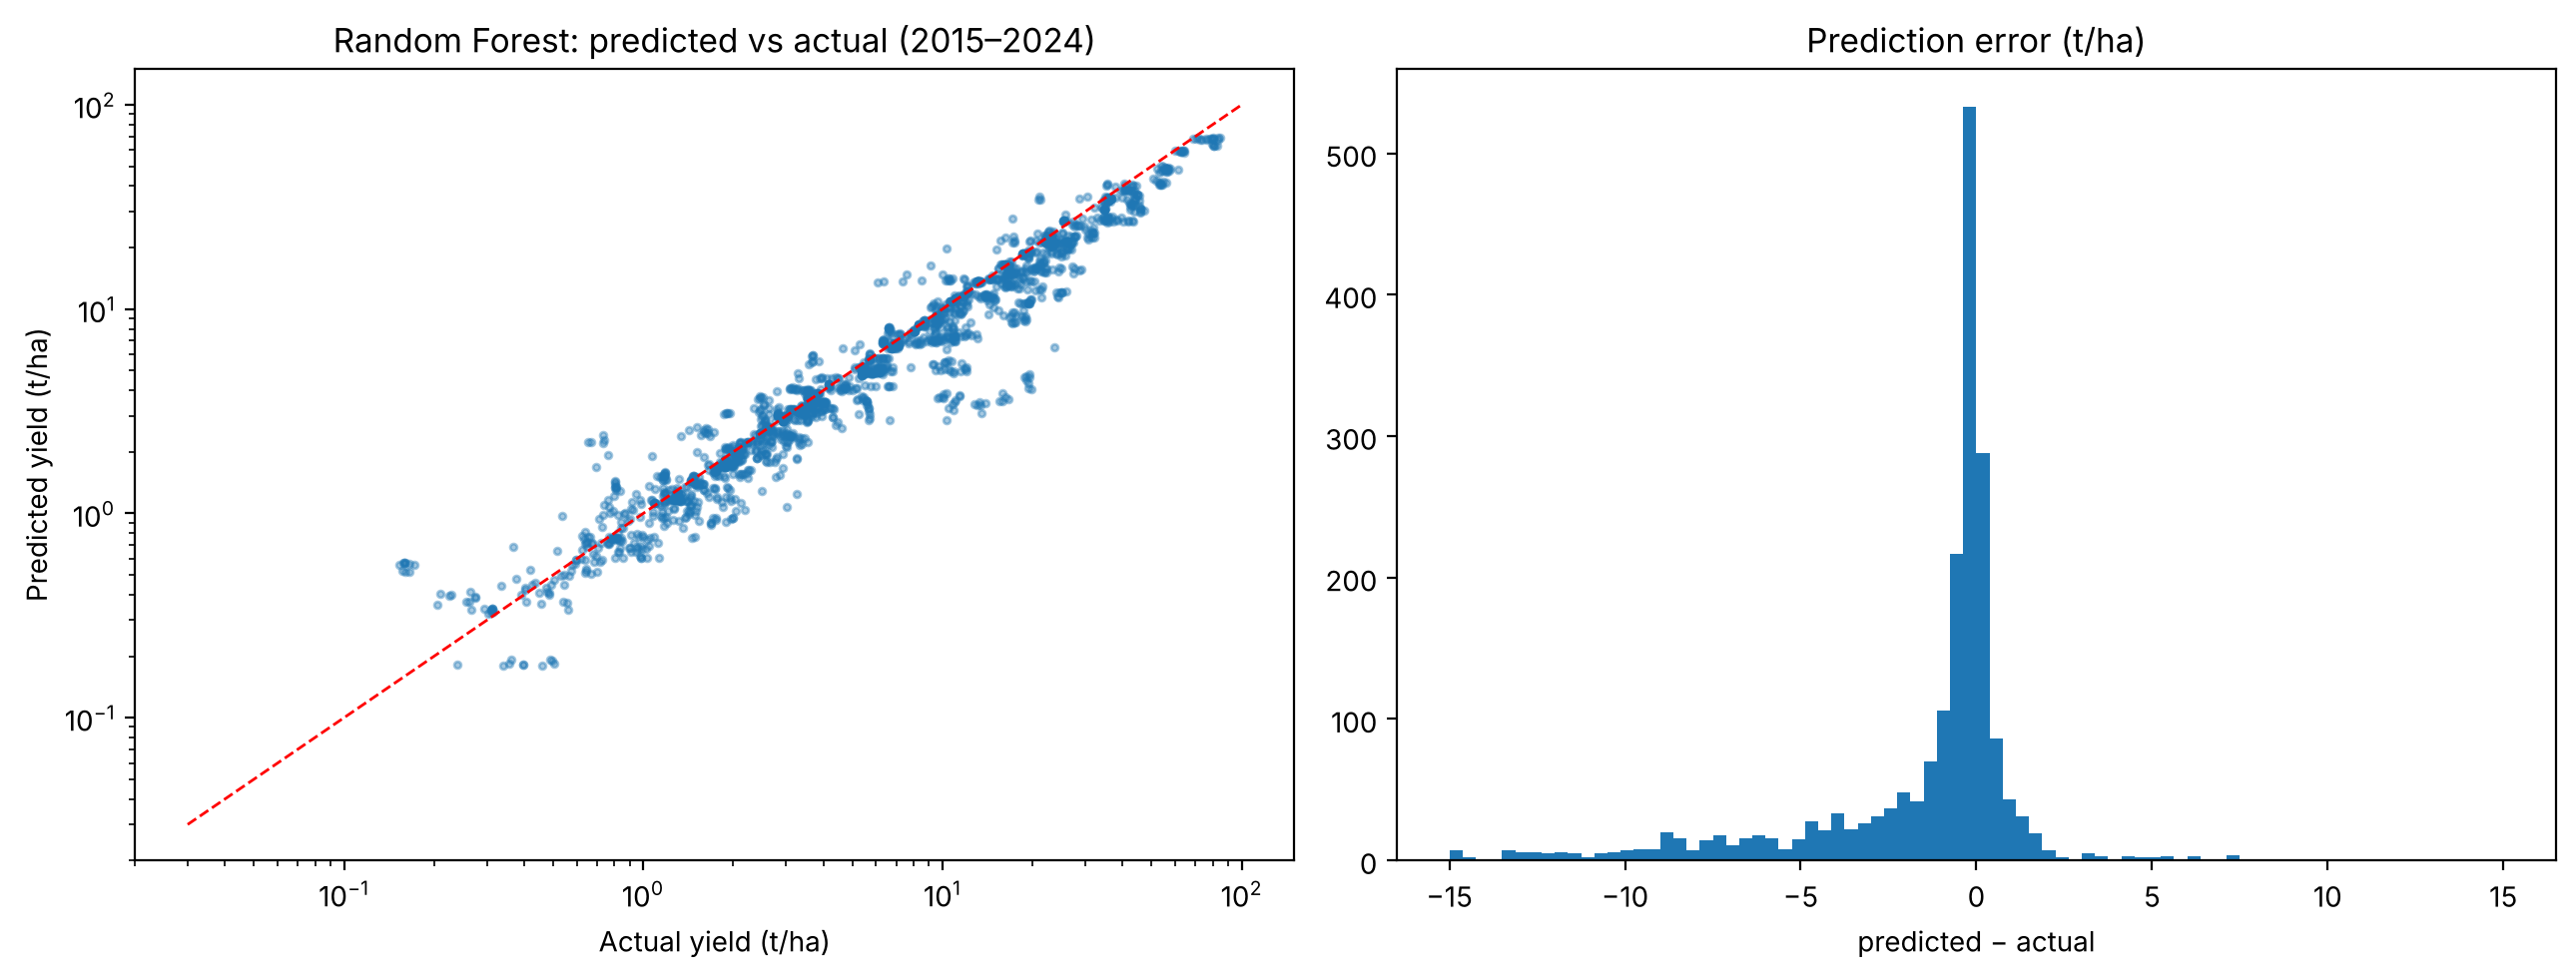

In [14]:
best_name = results_df.drop("Baseline (crop average)")["R2"].idxmax()
best_pipe, best_pred = fitted[best_name]
print("Best model:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, best_pred, s=6, alpha=0.4)
lim = [0.03, 100]
ax[0].plot(lim, lim, "r--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set_xlabel("Actual yield (t/ha)"); ax[0].set_ylabel("Predicted yield (t/ha)")
ax[0].set_title(f"{best_name}: predicted vs actual (2015–2024)")

residual = best_pred - y_test
ax[1].hist(residual, bins=80, range=(-15, 15))
ax[1].set_title("Prediction error (t/ha)"); ax[1].set_xlabel("predicted − actual")
plt.tight_layout(); plt.show()

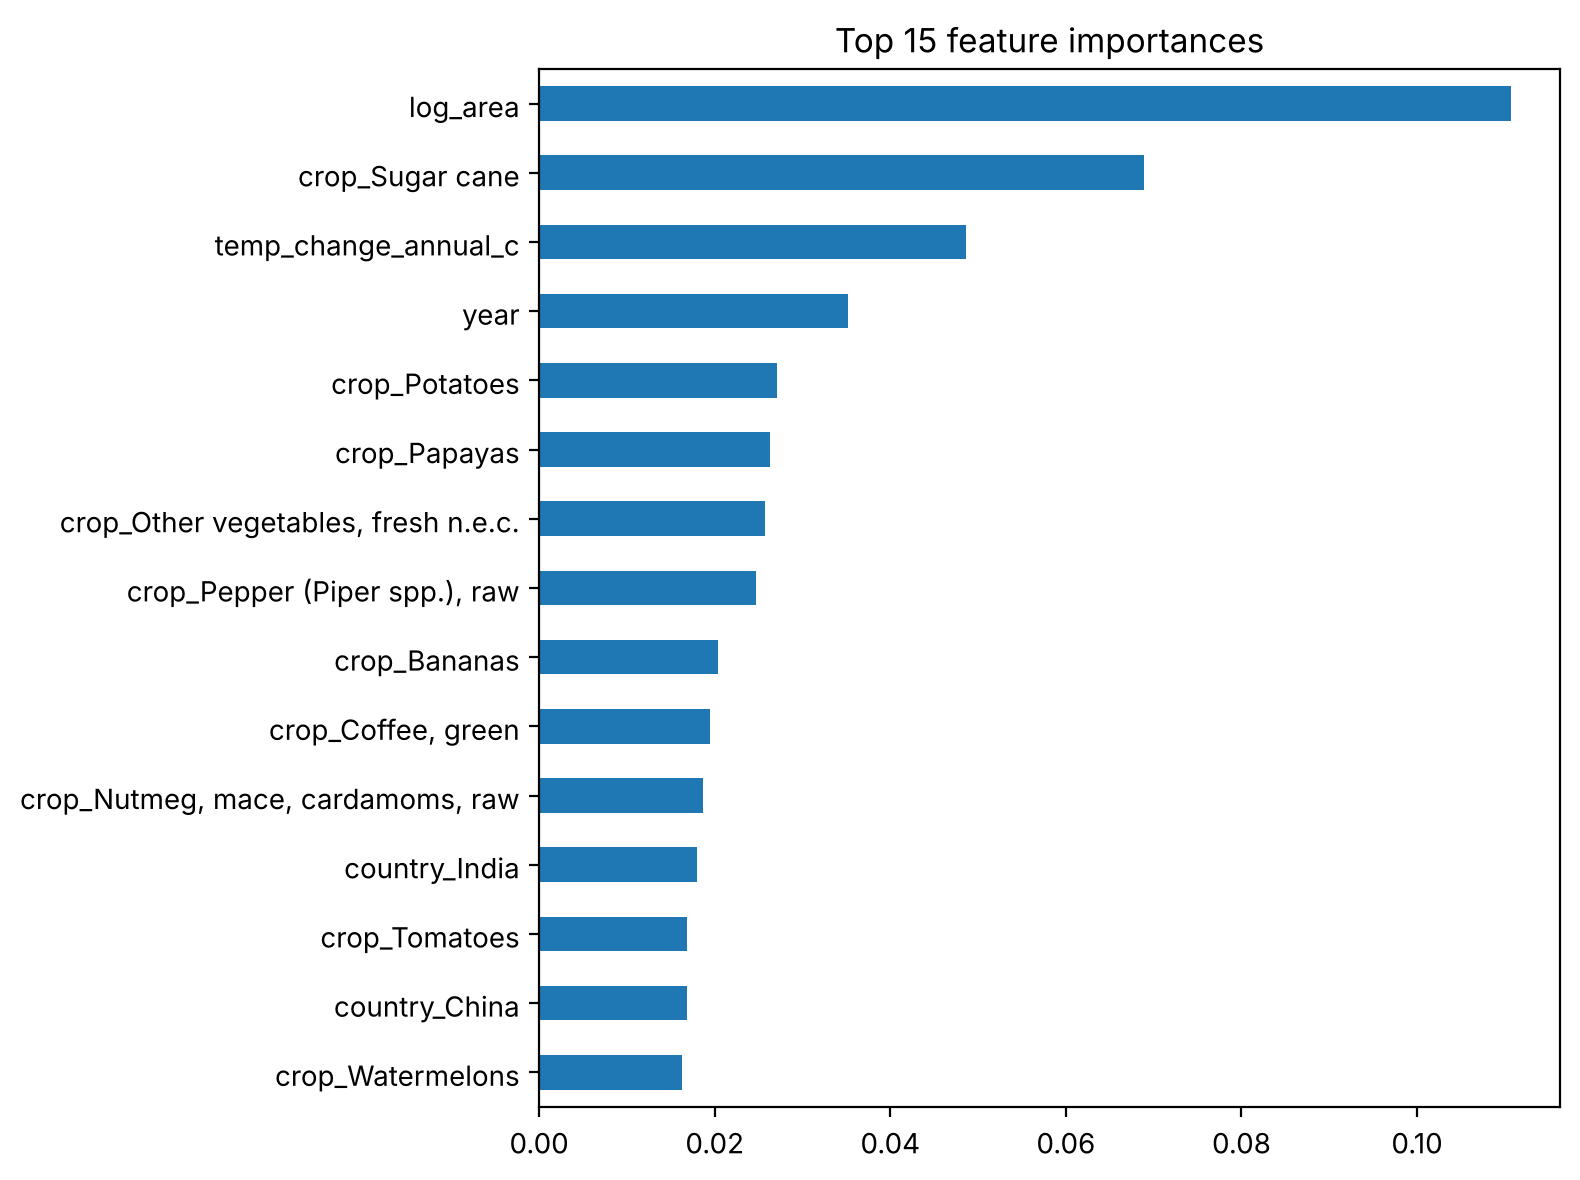

In [15]:
# Which features does the Random Forest rely on?
rf_pipe = fitted["Random Forest"][0]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)
imp.index = imp.index.str.replace("cat__", "").str.replace("num__", "")
imp.sort_values().tail(15).plot.barh(figsize=(8, 6), title="Top 15 feature importances")
plt.tight_layout(); plt.show()

**Interpretation:** the Random Forest explains the most variance on unseen future years and cuts the
baseline's error substantially. Crop identity and harvested area dominate; year captures the
technology trend, and the seasonal temperature features add smaller adjustments.

## Step 9 — Hyperparameter Tuning

`RandomizedSearchCV` with **TimeSeriesSplit** (each fold trains on earlier years and validates on later ones,
matching how the model is used).

In [16]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

rf_pipeline = Pipeline([("prep", preprocessor),
                        ("model", RandomForestRegressor(n_jobs=-1, random_state=42))])

param_dist = {
    "model__n_estimators":     [100, 150, 200],
    "model__max_features":     [0.3, 0.5, 1.0],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_depth":        [None, 20, 30],
}

search = RandomizedSearchCV(rf_pipeline, param_dist, n_iter=8, cv=TimeSeriesSplit(n_splits=3),
                            scoring="r2", random_state=42, n_jobs=1, verbose=1)
t0 = time.time()
search.fit(X_train, y_train)
print(f"search took {time.time() - t0:.0f}s")
print("best params :", search.best_params_)
print("best CV R²  :", round(search.best_score_, 4), "(log scale)")

Fitting 3 folds for each of 8 candidates, totalling 24 fits


search took 34s
best params : {'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': None}
best CV R²  : 0.8077 (log scale)


In [17]:
tuned_pred = np.expm1(search.best_estimator_.predict(X_test))
final_row = evaluate("Random Forest (tuned)", y_test, tuned_pred)
results_df.loc["Random Forest (tuned)"] = [round(final_row[k], 3) for k in ["R2", "MAE", "RMSE"]]
results_df.sort_values("R2", ascending=False)

,R2,MAE,RMSE
model,,,
Random Forest,0.926,2.026,3.826
Random Forest (tuned),0.898,2.382,4.482
Hist Gradient Boosting,0.807,3.236,6.164
Ridge Regression,0.794,3.351,6.366
Baseline (crop average),0.671,4.303,8.044


In [18]:
# Keep whichever Random Forest scored better on the held-out test years
default_rf = results_df.loc["Random Forest"]
tuned_rf   = results_df.loc["Random Forest (tuned)"]
if tuned_rf["R2"] >= default_rf["R2"]:
    best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    chosen, test_metrics = "tuned", tuned_rf
else:
    best_params = {"n_estimators": 150, "max_features": 1.0, "min_samples_leaf": 1, "max_depth": None}
    chosen, test_metrics = "default", default_rf
print("Using", chosen, "parameters:", best_params)
print(test_metrics)

Using default parameters: {'n_estimators': 150, 'max_features': 1.0, 'min_samples_leaf': 1, 'max_depth': None}
R2      0.926
MAE     2.026
RMSE    3.826
Name: Random Forest, dtype: float64


**Note on tuning:** the search picks the settings with the best *cross-validation* score inside the
training years. Those settings don't always win on the final test years. When the default settings
score better on 2015–2024, we keep the defaults. Tuning means *checking*; it doesn't always change the answer.

## Step 10 — Model Saving

The final model is **re-trained on all years (1961–2024)** with the chosen parameters so it learns the most
recent trend, then saved with `joblib`. The whole `Pipeline` is saved, so the API sends raw inputs
(country, crop, …) and the encoding/scaling happens inside the model.

A small `model_meta.json` is saved too: crop lists, year range, temperature values per country/year and the
test metrics. The frontend uses it to fill dropdowns.

In [19]:
import joblib, json, os, sklearn

final_model = Pipeline([("prep", preprocessor),
                        ("model", RandomForestRegressor(n_jobs=-1, random_state=42, **best_params))])
final_model.fit(df[FEATURES], np.log1p(df[TARGET]))

os.makedirs("../model", exist_ok=True)
joblib.dump(final_model, "../model/crop_yield_model.joblib", compress=3)

temp_cols = ["temp_change_annual_c", "temp_change_djf_c", "temp_change_mam_c",
             "temp_change_jja_c", "temp_change_son_c"]
weather_by_year = (df.groupby(["country", "year"])[temp_cols].first().round(3)
                     .reset_index())
recent = df[df["year"] >= df["year"].max() - 4]

meta = {
    "model": "RandomForestRegressor (log1p target)",
    "params": {k: (None if v is None else v) for k, v in best_params.items()},
    "sklearn_version": sklearn.__version__,
    "features": FEATURES,
    "year_range": [int(df.year.min()), int(df.year.max())],
    "test_years": [2015, 2024],
    "test_metrics": {k: float(test_metrics[k]) for k in ["R2", "MAE", "RMSE"]},
    "baseline_metrics": {k: float(results_df.loc["Baseline (crop average)", k]) for k in ["R2", "MAE", "RMSE"]},
    "crops_by_country": {c: sorted(df.loc[df.country == c, "crop"].unique().tolist())
                         for c in sorted(df.country.unique())},
    "typical_area_ha": {c: recent[recent.country == c].groupby("crop")["area_harvested_ha"]
                              .median().round(0).to_dict()
                        for c in sorted(df.country.unique())},
    "weather": {c: {int(r.year): [r[t] for t in temp_cols]
                    for _, r in weather_by_year[weather_by_year.country == c].iterrows()}
                for c in sorted(df.country.unique())},
    "temp_columns": temp_cols,
}
with open("../model/model_meta.json", "w") as f:
    json.dump(meta, f)

# history file for the frontend chart
df[["country", "crop", "year", "yield_t_ha"]].to_csv("../model/yield_history.csv", index=False)

print("saved:", os.path.getsize("../model/crop_yield_model.joblib") / 1e6, "MB")

saved: 42.941778 MB


In [20]:
# Sanity check: reload and predict one example
loaded = joblib.load("../model/crop_yield_model.joblib")
sample = pd.DataFrame([{"country": "India", "crop": "Rice", "year": 2024,
                        "log_area": np.log1p(47_000_000),
                        "temp_change_annual_c": 1.0, "temp_change_djf_c": 1.0, "temp_change_mam_c": 1.0,
                        "temp_change_jja_c": 0.8, "temp_change_son_c": 1.1}])
print("Predicted India rice yield 2024:", round(float(np.expm1(loaded.predict(sample))[0]), 3), "t/ha")
print("Actual:", df[(df.country == "India") & (df.crop == "Rice") & (df.year == 2024)][TARGET].values)

Predicted India rice yield 2024: 4.198 t/ha
Actual: [4.3132]


**Next:** run the app → see `README.md` (Steps 11–16).